# AgroRiesgo IA — Predicción del riesgo de pérdida de cultivos en la agricultura colombiana
### Implementación de la solución · Aprendizaje Supervisado (Clasificación + Regresión)

**Asignatura:** Inteligencia Artificial

**Integrantes:** Verona Andrés · Vargas Dadier · Ballesteros Carlos · Miranda Deiver

---

### Objetivo del notebook

Entrenar y evaluar los modelos de aprendizaje supervisado que permiten a **AgroRiesgo IA** anticipar si un cultivo
en un municipio colombiano tendrá una **pérdida alta de área en el campo** (área que se sembró pero no se alcanzó a
cosechar), a partir de los datos oficiales de las **Evaluaciones Agropecuarias Municipales (EVA)** del Ministerio de
Agricultura y Desarrollo Rural, publicados en el portal **datos.gov.co**.

### Cómo se conecta el modelo con el problema

El modelo aprende, con más de 120.000 registros reales de cultivos por municipio entre 2006 y 2017, qué
combinaciones de **cultivo, departamento, temporada, tamaño de la siembra e historial de pérdidas** anteceden a una
pérdida alta. Con ese conocimiento, la plataforma asigna un **nivel de riesgo** a cada siembra nueva, recomienda
medidas preventivas al productor y **prioriza las visitas** de la UMATA, el ICA o la secretaría de agricultura hacia
los municipios y cultivos con mayor riesgo.

### Planteamiento

| | |
|---|---|
| **Tipo de aprendizaje** | Supervisado (cada registro tiene su resultado conocido) |
| **Problema principal** | Clasificación binaria: `perdida_alta` (1 = se perdió el 20 % o más del área sembrada) |
| **Problema complementario** | Regresión: rendimiento esperado (t/ha) |
| **Variables de entrada X** | Cultivo, grupo, departamento, temporada, ciclo, año, área sembrada e historial de pérdidas |
| **Fuente de datos** | datos.gov.co — *Evaluaciones Agropecuarias Municipales EVA* (Ministerio de Agricultura) |

---
## 1. Importación de librerías

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, classification_report, confusion_matrix,
                             r2_score, mean_absolute_error, mean_squared_error)

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)
np.random.seed(42)
print('Librerias cargadas correctamente')

Librerias cargadas correctamente


---
## 2. Carga del conjunto de datos

**Fuente:** Portal de Datos Abiertos de Colombia (datos.gov.co) — *Evaluaciones Agropecuarias Municipales EVA*,
publicado por el **Ministerio de Agricultura y Desarrollo Rural**.

**Enlace:** https://www.datos.gov.co/Agricultura-y-Desarrollo-Rural/Evaluaciones-Agropecuarias-Municipales-EVA/2pnw-mmge

**Archivo:** `Evaluaciones_Agropecuarias_Municipales_EVA.csv` (formato CSV, separado por comas).

La celda siguiente busca el archivo en la carpeta del notebook; si no está, en Google Colab abre el selector para
subirlo.

In [2]:
ARCHIVO = 'Evaluaciones_Agropecuarias_Municipales_EVA.csv'

if not os.path.exists(ARCHIVO):
    try:
        from google.colab import files
        subidos = files.upload()
        ARCHIVO = list(subidos.keys())[0]
    except ImportError:
        raise FileNotFoundError('Coloque el archivo CSV en la carpeta del notebook o ejecutelo en Google Colab.')

df = pd.read_csv(ARCHIVO)
print('Registros cargados :', df.shape[0])
print('Columnas           :', df.shape[1])
df.head(3)

Registros cargados : 206068
Columnas           : 17


,CÓD. \nDEP.,DEPARTAMENTO,CÓD. MUN.,MUNICIPIO,GRUPO \nDE CULTIVO,SUBGRUPO \nDE CULTIVO,CULTIVO,DESAGREGACIÓN REGIONAL Y/O SISTEMA PRODUCTIVO,AÑO,PERIODO,Área Sembrada\n(ha),Área Cosechada\n(ha),Producción\n(t),Rendimiento\n(t/ha),ESTADO FISICO PRODUCCION,NOMBRE \nCIENTIFICO,CICLO DE CULTIVO
0,15,BOYACA,15114,BUSBANZA,HORTALIZAS,ACELGA,ACELGA,ACELGA,2006,2006B,2,1,1,1.00,FRUTO FRESCO,BETA VULGARIS,TRANSITORIO
1,25,CUNDINAMARCA,25754,SOACHA,HORTALIZAS,ACELGA,ACELGA,ACELGA,2006,2006B,82,80,1440,18.00,FRUTO FRESCO,BETA VULGARIS,TRANSITORIO
2,25,CUNDINAMARCA,25214,COTA,HORTALIZAS,ACELGA,ACELGA,ACELGA,2006,2006B,2,2,26,17.33,FRUTO FRESCO,BETA VULGARIS,TRANSITORIO


Los nombres originales tienen tildes, mayúsculas y saltos de línea (por ejemplo `"Área Sembrada\n(ha)"`). Se
renombran a nombres cortos para trabajar con comodidad.

In [3]:
df.columns = ['cod_dep', 'departamento', 'cod_mun', 'municipio', 'grupo', 'subgrupo', 'cultivo',
              'desagregacion', 'anio', 'periodo', 'area_sembrada', 'area_cosechada', 'produccion',
              'rendimiento', 'estado_fisico', 'nombre_cientifico', 'ciclo']
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 206068 entries, 0 to 206067
Data columns (total 17 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   cod_dep            206068 non-null  int64  
 1   departamento       206068 non-null  str    
 2   cod_mun            206068 non-null  int64  
 3   municipio          206067 non-null  str    
 4   grupo              206068 non-null  str    
 5   subgrupo           206068 non-null  str    
 6   cultivo            206068 non-null  str    
 7   desagregacion      206068 non-null  str    
 8   anio               206068 non-null  int64  
 9   periodo            206068 non-null  str    
 10  area_sembrada      206068 non-null  int64  
 11  area_cosechada     206068 non-null  int64  
 12  produccion         206068 non-null  int64  
 13  rendimiento        202635 non-null  float64
 14  estado_fisico      206068 non-null  str    
 15  nombre_cientifico  203211 non-null  str    
 16  ciclo        

---
## 3. Exploración inicial de los datos

In [4]:
print('Anos              :', df['anio'].min(), 'a', df['anio'].max())
print('Departamentos     :', df['departamento'].nunique())
print('Municipios        :', df['cod_mun'].nunique())
print('Cultivos distintos:', df['cultivo'].nunique())
print()
print('Registros por ciclo de cultivo:')
print(df['ciclo'].value_counts().to_string())
print()
print('Registros por grupo de cultivo:')
print(df['grupo'].value_counts().to_string())

Anos              : 2006 a 2018
Departamentos     : 32
Municipios        : 1105
Cultivos distintos: 223

Registros por ciclo de cultivo:
ciclo
TRANSITORIO    108943
PERMANENTE      82643
ANUAL           14482

Registros por grupo de cultivo:


grupo
FRUTALES                                            50236
CEREALES                                            36045
HORTALIZAS                                          32032
TUBERCULOS Y PLATANOS                               30664
LEGUMINOSAS                                         26368
OTROS PERMANENTES                                   21813
FIBRAS                                               1977
OLEAGINOSAS                                          1967
PLANTAS AROMATICAS, CONDIMENTARIAS Y MEDICINALES     1686
FORESTALES                                           1327
FLORES Y FOLLAJES                                     981
OTROS TRANSITORIOS                                    956
HONGOS                                                 16


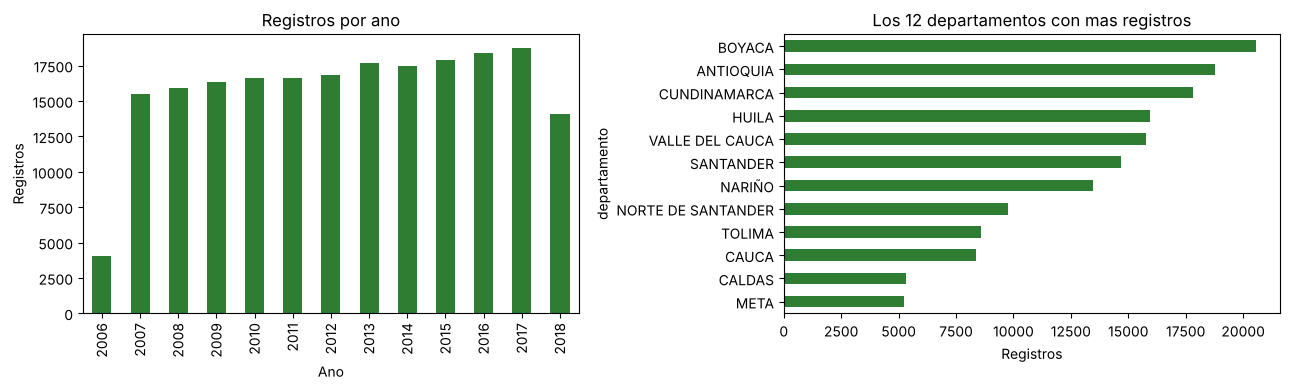

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
df['anio'].value_counts().sort_index().plot(kind='bar', ax=ax[0], color='#2E7D32')
ax[0].set_title('Registros por ano'); ax[0].set_xlabel('Ano'); ax[0].set_ylabel('Registros')
df['departamento'].value_counts().head(12).sort_values().plot(kind='barh', ax=ax[1], color='#2E7D32')
ax[1].set_title('Los 12 departamentos con mas registros'); ax[1].set_xlabel('Registros')
plt.tight_layout(); plt.show()

---
## 4. Limpieza de los datos

Se revisan: **filas duplicadas**, **valores nulos**, **registros inválidos** y **valores atípicos**, y se delimita
el alcance a los cultivos para los que la pérdida de área tiene sentido.

### 4.1 Filas duplicadas

In [6]:
filas_iniciales = len(df)
print('Filas duplicadas:', df.duplicated().sum())
df = df.drop_duplicates()
print('Filas restantes :', len(df))

Filas duplicadas: 0


Filas restantes : 206068


### 4.2 Valores nulos

In [7]:
nulos = df.isnull().sum()
print(nulos[nulos > 0].to_string())

municipio               1
rendimiento          3433
nombre_cientifico    2857


- `nombre_cientifico` (2.857 nulos): **no se usa** en el modelo, por lo que no requiere tratamiento.
- `rendimiento` (3.433 nulos): solo se usa en el módulo de regresión; allí se excluyen las filas sin rendimiento,
  porque rellenarlo equivaldría a inventar la respuesta que el modelo debe aprender.
- `municipio` (1 nulo): el modelo trabaja con el código del municipio (`cod_mun`), que no tiene nulos; el nombre
  faltante se completa a partir de ese código.

In [8]:
nombres_mun = df.dropna(subset=['municipio']).groupby('cod_mun')['municipio'].agg(lambda s: s.mode()[0])
df['municipio'] = df['municipio'].fillna(df['cod_mun'].map(nombres_mun)).fillna('DESCONOCIDO')
print('Nulos en municipio despues de completar:', df['municipio'].isnull().sum())

Nulos en municipio despues de completar: 0


### 4.3 Alcance: solo cultivos transitorios y anuales

En los **cultivos permanentes** (café, cacao, frutales, palma…) el área sembrada incluye plantaciones nuevas que
todavía **no están en edad de producir**, de modo que *área sembrada − área cosechada* no representa una pérdida.
En los **transitorios y anuales** (maíz, fríjol, papa, tomate, arroz, hortalizas…) lo que se siembra debería
cosecharse en la misma temporada: allí la diferencia sí mide el área que **se perdió en el campo**.

Además, la columna `cultivo` mezcla variantes que el Ministerio registra por separado (por ejemplo *maíz tradicional*
y *maíz tecnificado*, o *arroz riego* y *arroz secano*). Se toma la columna `desagregacion` como nombre del cultivo
para que cada fila sea una siembra distinta.

In [9]:
df['tasa_perdida_tmp'] = (df.area_sembrada - df.area_cosechada) / df.area_sembrada.replace(0, np.nan)
print('Pérdida media de área por ciclo (en %):')
print((df.groupby('ciclo')['tasa_perdida_tmp'].mean() * 100).round(1).to_string())

d = df[df['ciclo'].isin(['TRANSITORIO', 'ANUAL'])].drop(columns='tasa_perdida_tmp').copy()
print()
print('Registros de cultivos transitorios y anuales:', len(d))

# 'cultivo' agrupa variantes distintas (MAIZ = MAIZ TRADICIONAL + MAIZ TECNIFICADO) que aparecen como filas
# separadas del mismo municipio y temporada. La columna 'desagregacion' identifica cada variante, asi que se usa
# como cultivo para que cada fila sea una siembra unica.
d['cultivo'] = d['desagregacion']
print('Filas repetidas por municipio + cultivo + periodo:', d.duplicated(['cod_mun', 'cultivo', 'anio', 'periodo']).sum())
print('Cultivos (variantes) distintos:', d['cultivo'].nunique())

Pérdida media de área por ciclo (en %):
ciclo
ANUAL          11.0
PERMANENTE     21.6
TRANSITORIO     7.5

Registros de cultivos transitorios y anuales: 123425
Filas repetidas por municipio + cultivo + periodo: 0
Cultivos (variantes) distintos: 117


### 4.4 Registros inválidos

In [10]:
sin_siembra = (d.area_sembrada <= 0).sum()
inconsistentes = (d.area_cosechada > d.area_sembrada).sum()
print('Registros con area sembrada = 0             :', sin_siembra)
print('Registros con area cosechada > area sembrada:', inconsistentes)
d = d[(d.area_sembrada > 0) & (d.area_cosechada <= d.area_sembrada)].copy()
print('Registros validos                           :', len(d))

Registros con area sembrada = 0             : 560
Registros con area cosechada > area sembrada: 56


Registros validos                           : 122809


Con área sembrada igual a cero no se puede calcular la proporción perdida, y un área cosechada mayor que la sembrada
es una inconsistencia de registro. Ambos casos se eliminan.

### 4.5 Año 2018: datos incompletos

Al revisar la pérdida por año aparece un problema de calidad: en 2018 casi ningún registro tiene pérdida, mientras que
en los demás años la proporción está entre 9 % y 21 %. Además, 2018 tiene muchos menos registros. Todo indica que
para ese año se publicaron cifras **preliminares** (área cosechada igual a la sembrada), por lo que se excluye.

In [11]:
d['tasa_tmp'] = (d.area_sembrada - d.area_cosechada) / d.area_sembrada
por_anio = pd.DataFrame({'registros': d.groupby('anio').size(),
                         '% con perdida alta': ((d.tasa_tmp >= 0.20).groupby(d.anio).mean() * 100).round(1)})
print(por_anio.to_string())
d = d[d.anio <= 2017].drop(columns='tasa_tmp').copy()
print()
print('Registros despues de excluir 2018:', len(d))

      registros  % con perdida alta
anio                               
2006       4054                 9.4
2007       9373                11.1
2008       9574                12.7
2009       9741                14.7
2010       9969                20.2
2011       9922                21.5
2012      10013                16.9
2013      10597                13.1
2014      10327                16.7
2015      10667                19.7
2016      10944                15.4
2017      11133                14.4
2018       6495                 0.1

Registros despues de excluir 2018: 116314


### 4.6 Valores atípicos

El área sembrada es muy asimétrica: conviven siembras de 1 hectárea con otras de decenas de miles. Son registros
reales, por lo que **no se eliminan**; se usa su **logaritmo** para que los valores extremos no dominen al modelo.

Q1 = 9 ha · Q3 = 120 ha · IQR = 111 ha
Siembras atipicas (> Q3 + 1.5*IQR): 16910 (14.5%)


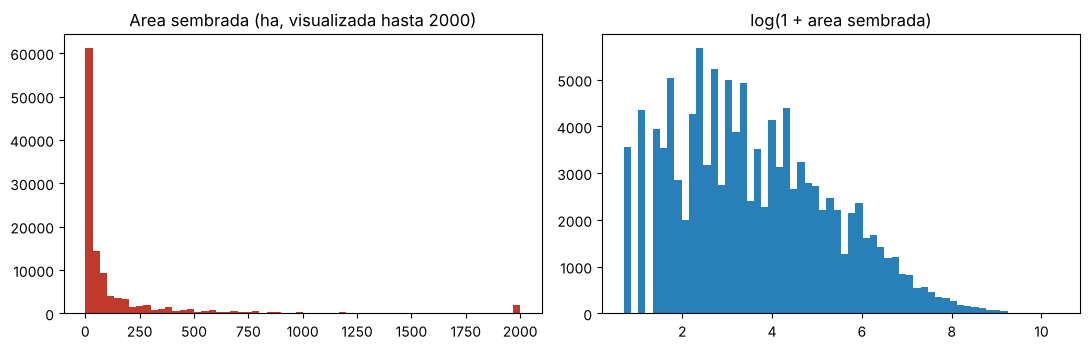

In [12]:
Q1, Q3 = d.area_sembrada.quantile([0.25, 0.75])
IQR = Q3 - Q1
atipicos = (d.area_sembrada > Q3 + 1.5 * IQR).sum()
print(f'Q1 = {Q1:.0f} ha · Q3 = {Q3:.0f} ha · IQR = {IQR:.0f} ha')
print('Siembras atipicas (> Q3 + 1.5*IQR):', atipicos, f'({atipicos / len(d):.1%})')

d['log_area_sembrada'] = np.log1p(d.area_sembrada)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(d.area_sembrada.clip(upper=2000), bins=60, color='#C0392B'); ax[0].set_title('Area sembrada (ha, visualizada hasta 2000)')
ax[1].hist(d.log_area_sembrada, bins=60, color='#2980B9'); ax[1].set_title('log(1 + area sembrada)')
plt.tight_layout(); plt.show()

---
## 5. Variable objetivo y ingeniería de variables

### 5.1 Variable objetivo `perdida_alta`

$$\text{tasa de pérdida} = \frac{\text{área sembrada} - \text{área cosechada}}{\text{área sembrada}}$$

Un registro se marca como **pérdida alta (1)** cuando se perdió **el 20 % o más** del área sembrada, es decir, al
menos una de cada cinco hectáreas. En caso contrario es **0**.

Distribucion de la variable objetivo:
perdida_alta
Sin perdida alta (0)    97896
Perdida alta (1)        18418
Proporcion con perdida alta: 15.83%
Hectareas perdidas en total : 1,773,894 ha


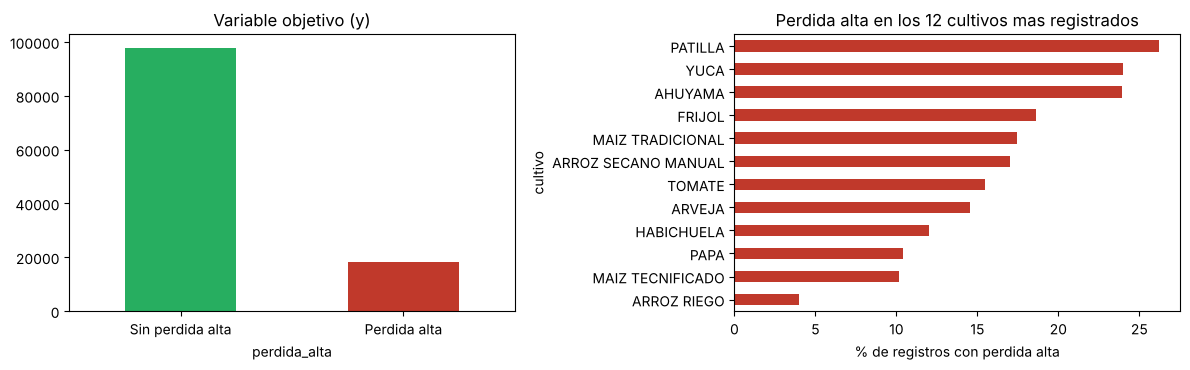

In [13]:
d['tasa_perdida'] = (d.area_sembrada - d.area_cosechada) / d.area_sembrada
d['perdida_alta'] = (d.tasa_perdida >= 0.20).astype(int)

print('Distribucion de la variable objetivo:')
print(d['perdida_alta'].value_counts().rename({0: 'Sin perdida alta (0)', 1: 'Perdida alta (1)'}).to_string())
print('Proporcion con perdida alta: {:.2%}'.format(d['perdida_alta'].mean()))
print('Hectareas perdidas en total : {:,.0f} ha'.format((d.area_sembrada - d.area_cosechada).sum()))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
d['perdida_alta'].value_counts().sort_index().plot(kind='bar', ax=ax[0], color=['#27AE60', '#C0392B'])
ax[0].set_xticklabels(['Sin perdida alta', 'Perdida alta'], rotation=0); ax[0].set_title('Variable objetivo (y)')
(d.groupby('cultivo')['perdida_alta'].mean().loc[d.cultivo.value_counts().head(12).index] * 100)\
    .sort_values().plot(kind='barh', ax=ax[1], color='#C0392B')
ax[1].set_xlabel('% de registros con perdida alta'); ax[1].set_title('Perdida alta en los 12 cultivos mas registrados')
plt.tight_layout(); plt.show()

### 5.2 Historial de pérdidas: ¿cómo le fue a ese cultivo en ese municipio antes?

La información más valiosa para anticipar una pérdida es lo que ocurrió **en temporadas anteriores** con el mismo
cultivo en el mismo municipio. Se construyen tres variables usando **solo registros pasados** (nunca el registro
actual ni el futuro, para no "hacer trampa"):

- `perdida_historica`: promedio de la tasa de pérdida de ese cultivo en ese municipio en todas las temporadas anteriores.
- `perdida_anterior`: tasa de pérdida de la temporada inmediatamente anterior.
- `temporadas_previas`: cuántas temporadas anteriores hay registradas (experiencia del municipio con ese cultivo).

Cuando no hay historial (primera vez que se registra el cultivo en el municipio) se usa la pérdida promedio general
y se marca con `sin_historial = 1`.

In [14]:
d['temporada'] = d['periodo'].astype(str).str[-1].map({'A': 'A', 'B': 'B'}).fillna('Anual')
d['orden'] = d['temporada'].map({'A': 1, 'B': 2, 'Anual': 3})
d = d.sort_values(['cod_mun', 'cultivo', 'anio', 'orden']).reset_index(drop=True)

grupo_mc = d.groupby(['cod_mun', 'cultivo'])['tasa_perdida']
d['perdida_historica'] = grupo_mc.transform(lambda s: s.shift(1).expanding().mean())
d['perdida_anterior']  = grupo_mc.shift(1)
d['temporadas_previas'] = d.groupby(['cod_mun', 'cultivo']).cumcount()
d['sin_historial'] = d['perdida_historica'].isnull().astype(int)

PERDIDA_MEDIA = d['tasa_perdida'].mean()
d['perdida_historica'] = d['perdida_historica'].fillna(PERDIDA_MEDIA)
d['perdida_anterior']  = d['perdida_anterior'].fillna(PERDIDA_MEDIA)

print('Registros sin historial previo: {:.1%}'.format(d['sin_historial'].mean()))
d[['municipio', 'cultivo', 'anio', 'temporada', 'tasa_perdida', 'perdida_historica', 'perdida_anterior']].head(8)

Registros sin historial previo: 8.9%


,municipio,cultivo,anio,temporada,tasa_perdida,perdida_historica,perdida_anterior
0,MEDELLIN,AJO,2006,B,0.0,0.084211,0.084211
1,MEDELLIN,AJO,2007,A,0.0,0.000000,0.000000
2,MEDELLIN,AJO,2007,B,0.0,0.000000,0.000000
3,MEDELLIN,AJO,2008,A,0.0,0.000000,0.000000
4,MEDELLIN,AJO,2008,B,0.0,0.000000,0.000000
5,MEDELLIN,AJO,2009,A,0.0,0.000000,0.000000
6,MEDELLIN,AJO,2009,B,0.0,0.000000,0.000000
7,MEDELLIN,AJO,2010,A,0.5,0.000000,0.000000


### 5.3 Variables categóricas

Departamento, grupo de cultivo, cultivo, temporada y ciclo son categorías **sin orden** (Antioquia no es "mayor" que
Boyacá). Si se codificaran con `LabelEncoder` (0, 1, 2…), los modelos interpretarían un orden que no existe; por eso
se convierten en variables indicadoras 0/1 con `pd.get_dummies` (*one-hot encoding*).

In [15]:
NUMERICAS   = ['log_area_sembrada', 'perdida_historica', 'perdida_anterior', 'temporadas_previas', 'sin_historial']
CATEGORICAS = ['departamento', 'grupo', 'cultivo', 'temporada', 'ciclo']

X = pd.concat([d[NUMERICAS], pd.get_dummies(d[CATEGORICAS], dtype=int)], axis=1)
y = d['perdida_alta']
print('Matriz X:', X.shape, '  Vector y:', y.shape)
d[NUMERICAS].describe().T.round(3)

Matriz X: (116314, 170)   Vector y: (116314,)


,count,mean,std,min,25%,50%,75%,max
log_area_sembrada,116314.0,3.623,1.733,0.693,2.303,3.434,4.796,10.374
perdida_historica,116314.0,0.078,0.100,0.000,0.000,0.051,0.100,1.000
perdida_anterior,116314.0,0.085,0.154,0.000,0.000,0.000,0.091,1.000
temporadas_previas,116314.0,7.730,6.017,0.000,3.000,7.000,12.000,22.000
sin_historial,116314.0,0.089,0.285,0.000,0.000,0.000,0.000,1.000


---
## 6. División en entrenamiento y prueba

Se reserva el **20 %** para prueba con `stratify=y`, para conservar la misma proporción de pérdidas altas en ambos
conjuntos, y `random_state=42` para que la división sea reproducible.

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print('Entrenamiento:', X_train.shape[0], 'registros')
print('Prueba       :', X_test.shape[0], 'registros')
print('Perdida alta en entrenamiento: {:.2%} · en prueba: {:.2%}'.format(y_train.mean(), y_test.mean()))

Entrenamiento: 93051 registros
Prueba       : 23263 registros
Perdida alta en entrenamiento: 15.83% · en prueba: 15.84%


**Clases desbalanceadas.** Solo el 15 % de los registros tiene pérdida alta. Un modelo que dijera siempre "no habrá
pérdida" acertaría el 85 % de las veces, pero sería **inútil**: nunca alertaría a nadie. Por eso:

- Se usa `class_weight='balanced'`, que da más peso a los casos de pérdida alta durante el entrenamiento.
- Además de la exactitud se reportan **precisión, sensibilidad (recall), F1 y AUC-ROC** de la clase *pérdida alta*.
  La sensibilidad es la más importante: mide qué porcentaje de las pérdidas reales logra detectar el modelo.

---
## 7. Modelo 1 — Árbol de Decisión (modelo principal)

Se elige como modelo principal por su **interpretabilidad**: su resultado se explica como reglas
(*"si el historial de pérdida es mayor a X y la temporada es B…"*), lo que permite justificar ante la UMATA o el
productor por qué un cultivo se considera de alto riesgo. Primero se analiza la profundidad con validación cruzada sobre el conjunto de entrenamiento para evitar el sobreajuste, sin usar el conjunto de prueba.

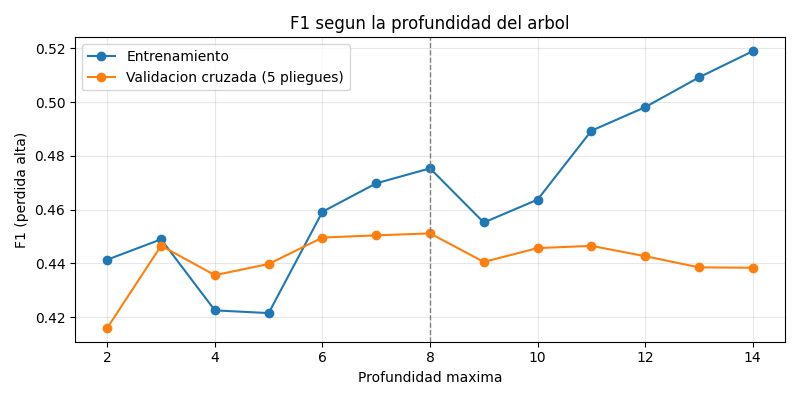

Mejor profundidad (validacion cruzada en entrenamiento): 8


In [17]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

# La profundidad se elige con validacion cruzada DENTRO del conjunto de entrenamiento,
# de modo que el conjunto de prueba no interviene en ninguna decision de ajuste.
profundidades = range(2, 15)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
f1_train, f1_val = [], []
for p in profundidades:
    m = DecisionTreeClassifier(max_depth=p, class_weight='balanced', random_state=42)
    f1_val.append(cross_val_score(m, X_train, y_train, cv=cv, scoring='f1', n_jobs=-1).mean())
    f1_train.append(f1_score(y_train, m.fit(X_train, y_train).predict(X_train)))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(profundidades, f1_train, marker='o', label='Entrenamiento')
ax.plot(profundidades, f1_val, marker='o', label='Validacion cruzada (5 pliegues)')
ax.axvline(list(profundidades)[int(np.argmax(f1_val))], color='gray', ls='--', lw=1)
ax.set_xlabel('Profundidad maxima'); ax.set_ylabel('F1 (perdida alta)')
ax.set_title('F1 segun la profundidad del arbol'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
MEJOR_PROFUNDIDAD = list(profundidades)[int(np.argmax(f1_val))]
print('Mejor profundidad (validacion cruzada en entrenamiento):', MEJOR_PROFUNDIDAD)

In [18]:
PROFUNDIDAD = MEJOR_PROFUNDIDAD
arbol = DecisionTreeClassifier(max_depth=PROFUNDIDAD, class_weight='balanced', random_state=42)
arbol.fit(X_train, y_train)
pred_arbol  = arbol.predict(X_test)
proba_arbol = arbol.predict_proba(X_test)[:, 1]

print(f'ARBOL DE DECISION (profundidad {PROFUNDIDAD}, class_weight=balanced)')
print('-' * 52)
print('Exactitud   (Accuracy) : {:.4f}'.format(accuracy_score(y_test, pred_arbol)))
print('Precision   (Precision): {:.4f}'.format(precision_score(y_test, pred_arbol)))
print('Sensibilidad (Recall)  : {:.4f}'.format(recall_score(y_test, pred_arbol)))
print('F1-Score               : {:.4f}'.format(f1_score(y_test, pred_arbol)))
print('AUC - ROC              : {:.4f}'.format(roc_auc_score(y_test, proba_arbol)))
print()
print(classification_report(y_test, pred_arbol, target_names=['Sin perdida alta', 'Perdida alta']))

ARBOL DE DECISION (profundidad 8, class_weight=balanced)
----------------------------------------------------
Exactitud   (Accuracy) : 0.7736
Precision   (Precision): 0.3667
Sensibilidad (Recall)  : 0.5909
F1-Score               : 0.4526
AUC - ROC              : 0.7671

                  precision    recall  f1-score   support

Sin perdida alta       0.91      0.81      0.86     19579
    Perdida alta       0.37      0.59      0.45      3684

        accuracy                           0.77     23263
       macro avg       0.64      0.70      0.65     23263
    weighted avg       0.83      0.77      0.79     23263



Variables mas influyentes (%):
perdida_anterior                   61.98
perdida_historica                  19.07
log_area_sembrada                   4.06
temporadas_previas                  2.82
temporada_Anual                     2.11
temporada_B                         2.01
departamento_MAGDALENA              1.58
departamento_ATLANTICO              1.24
departamento_BOLIVAR                0.83
departamento_NORTE DE SANTANDER     0.78


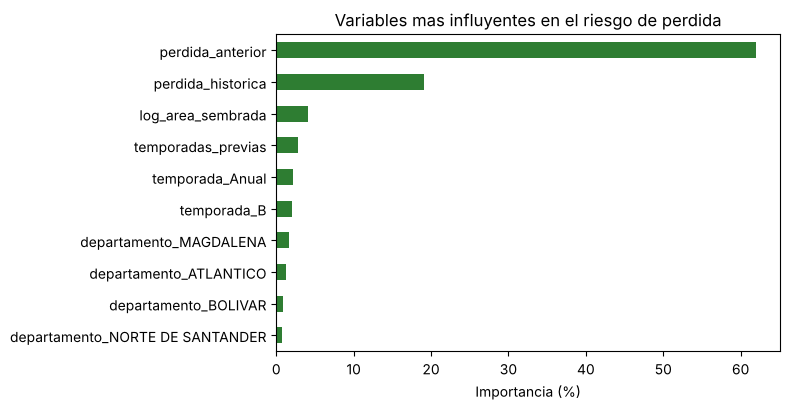

In [19]:
importancias = pd.Series(arbol.feature_importances_, index=X.columns).sort_values(ascending=False)
print('Variables mas influyentes (%):')
print((importancias.head(10) * 100).round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 4.2))
(importancias.head(10) * 100).sort_values().plot(kind='barh', ax=ax, color='#2E7D32')
ax.set_xlabel('Importancia (%)'); ax.set_title('Variables mas influyentes en el riesgo de perdida')
plt.tight_layout(); plt.show()

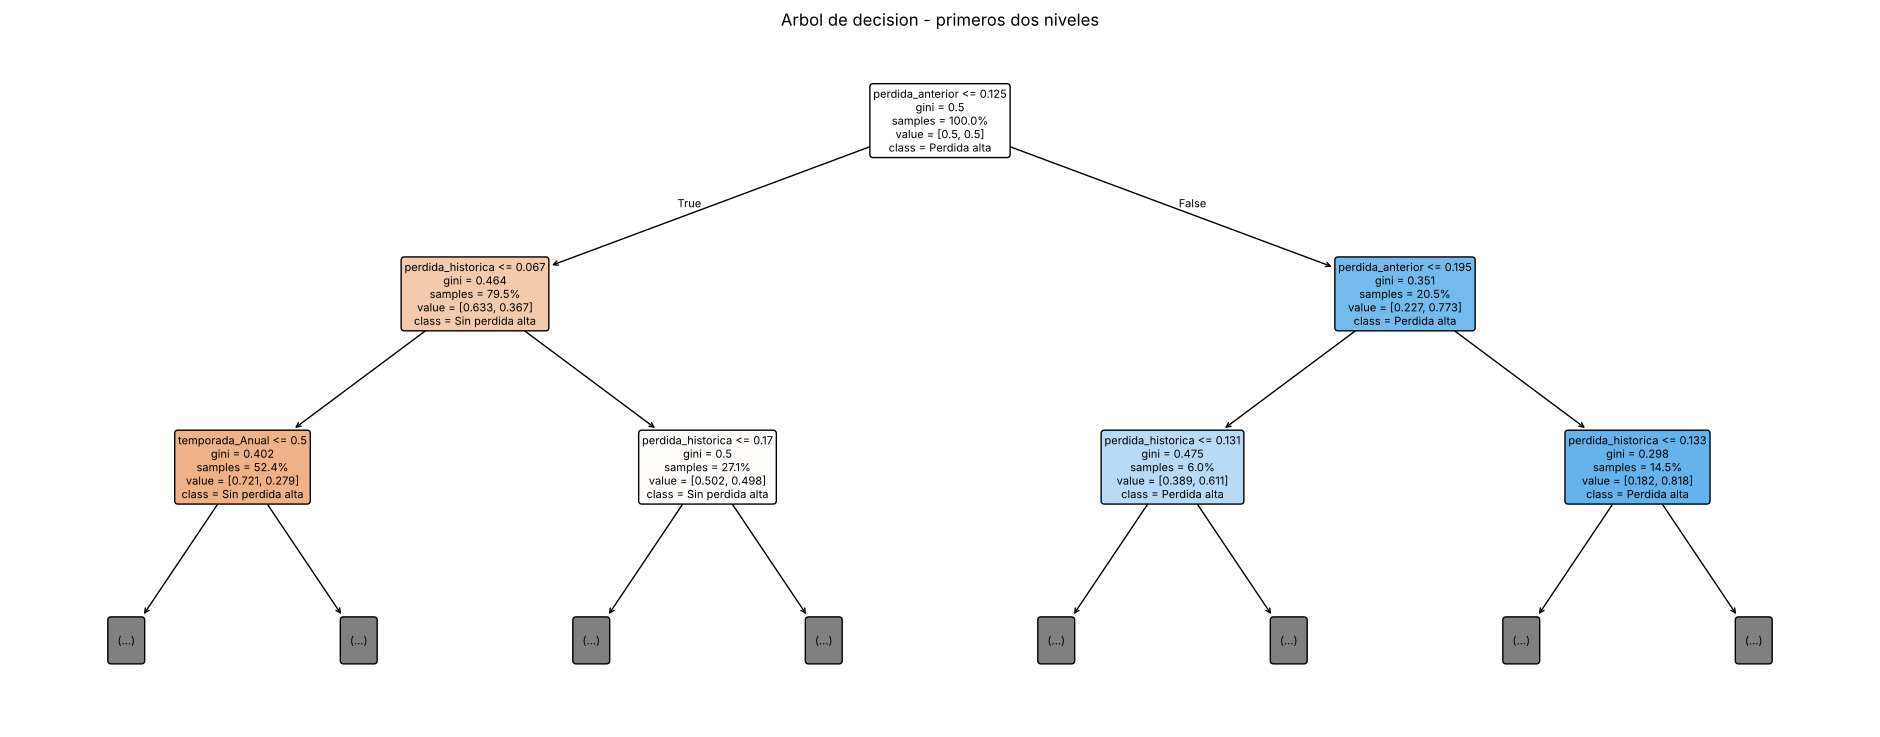

In [20]:
plt.figure(figsize=(24, 9))
plot_tree(arbol, feature_names=list(X.columns), class_names=['Sin perdida alta', 'Perdida alta'],
          filled=True, rounded=True, fontsize=8, max_depth=2, proportion=True)
plt.title('Arbol de decision - primeros dos niveles')
plt.show()

---
## 8. Modelo 2 — Regresión Logística

Modela la **probabilidad** de pérdida alta mediante la función sigmoide. Es sensible a la escala de las variables,
por lo que se estandarizan con `StandardScaler` (ajustado solo con el entrenamiento).

In [21]:
escalador = StandardScaler().fit(X_train)
X_train_esc, X_test_esc = escalador.transform(X_train), escalador.transform(X_test)

log_reg = LogisticRegression(max_iter=3000, class_weight='balanced', random_state=42)
log_reg.fit(X_train_esc, y_train)
pred_log  = log_reg.predict(X_test_esc)
proba_log = log_reg.predict_proba(X_test_esc)[:, 1]

print('REGRESION LOGISTICA')
print('-' * 52)
print('Exactitud   (Accuracy) : {:.4f}'.format(accuracy_score(y_test, pred_log)))
print('Precision   (Precision): {:.4f}'.format(precision_score(y_test, pred_log)))
print('Sensibilidad (Recall)  : {:.4f}'.format(recall_score(y_test, pred_log)))
print('F1-Score               : {:.4f}'.format(f1_score(y_test, pred_log)))
print('AUC - ROC              : {:.4f}'.format(roc_auc_score(y_test, proba_log)))

REGRESION LOGISTICA
----------------------------------------------------
Exactitud   (Accuracy) : 0.7572
Precision   (Precision): 0.3514
Sensibilidad (Recall)  : 0.6306
F1-Score               : 0.4513
AUC - ROC              : 0.7679


---
## 9. Modelo 3 — K Vecinos más Cercanos (KNN)

Clasifica un registro según lo que ocurrió en los **k registros más parecidos**. Usa las variables estandarizadas.
Con más de 98.000 registros de entrenamiento, la predicción puede tardar algunos segundos.

In [22]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_esc, y_train)
pred_knn  = knn.predict(X_test_esc)
proba_knn = knn.predict_proba(X_test_esc)[:, 1]

print('KNN (k = 5)')
print('-' * 52)
print('Exactitud   (Accuracy) : {:.4f}'.format(accuracy_score(y_test, pred_knn)))
print('Precision   (Precision): {:.4f}'.format(precision_score(y_test, pred_knn)))
print('Sensibilidad (Recall)  : {:.4f}'.format(recall_score(y_test, pred_knn)))
print('F1-Score               : {:.4f}'.format(f1_score(y_test, pred_knn)))
print('AUC - ROC              : {:.4f}'.format(roc_auc_score(y_test, proba_knn)))

KNN (k = 5)
----------------------------------------------------
Exactitud   (Accuracy) : 0.8395
Precision   (Precision): 0.4883
Sensibilidad (Recall)  : 0.2788
F1-Score               : 0.3549
AUC - ROC              : 0.7326


---
## 10. Evaluación comparativa de los clasificadores

In [23]:
def metricas(pred, proba):
    return [accuracy_score(y_test, pred), precision_score(y_test, pred), recall_score(y_test, pred),
            f1_score(y_test, pred), roc_auc_score(y_test, proba)]

comparativo = pd.DataFrame({
    'Arbol de Decision'  : metricas(pred_arbol, proba_arbol),
    'Regresion Logistica': metricas(pred_log, proba_log),
    'KNN (k=5)'          : metricas(pred_knn, proba_knn),
}, index=['Exactitud', 'Precision', 'Sensibilidad', 'F1-Score', 'AUC-ROC']).round(4)

linea_base = 1 - y_test.mean()
print('Linea base (decir siempre "sin perdida alta"): exactitud {:.4f}, sensibilidad 0.0000'.format(linea_base))
comparativo

Linea base (decir siempre "sin perdida alta"): exactitud 0.8416, sensibilidad 0.0000


,Arbol de Decision,Regresion Logistica,KNN (k=5)
Exactitud,0.7736,0.7572,0.8395
Precision,0.3667,0.3514,0.4883
Sensibilidad,0.5909,0.6306,0.2788
F1-Score,0.4526,0.4513,0.3549
AUC-ROC,0.7671,0.7679,0.7326


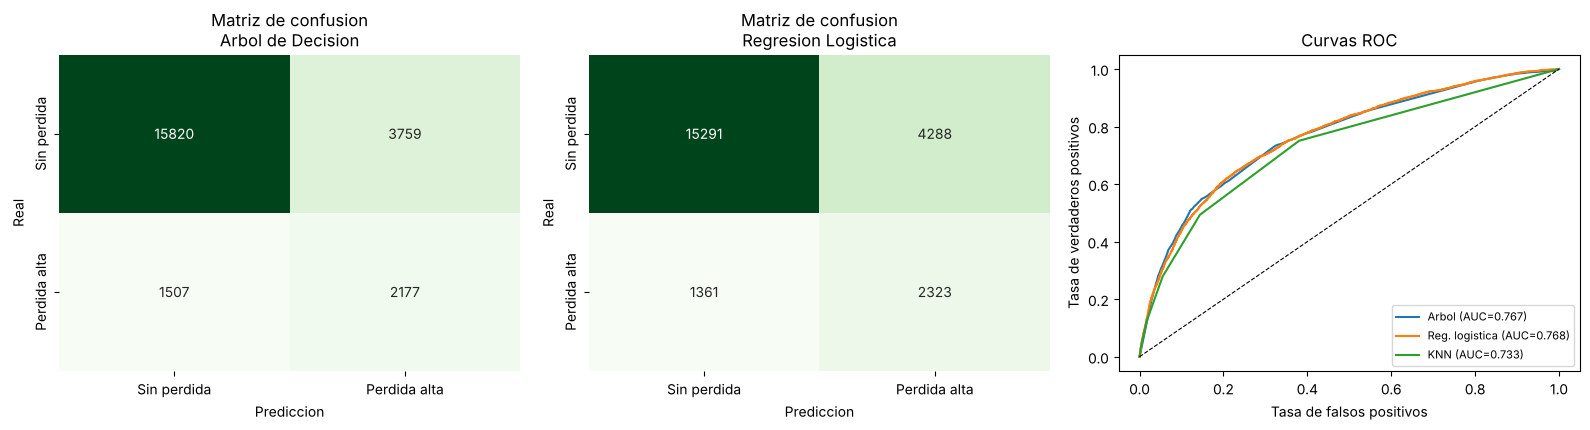

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
for i, (nombre, pred) in enumerate([('Arbol de Decision', pred_arbol), ('Regresion Logistica', pred_log)]):
    mc = confusion_matrix(y_test, pred)
    sns.heatmap(mc, annot=True, fmt='d', cmap='Greens', cbar=False, ax=ax[i],
                xticklabels=['Sin perdida', 'Perdida alta'], yticklabels=['Sin perdida', 'Perdida alta'])
    ax[i].set_title(f'Matriz de confusion\n{nombre}'); ax[i].set_xlabel('Prediccion'); ax[i].set_ylabel('Real')
for nombre, proba in [('Arbol', proba_arbol), ('Reg. logistica', proba_log), ('KNN', proba_knn)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax[2].plot(fpr, tpr, label=f'{nombre} (AUC={roc_auc_score(y_test, proba):.3f})')
ax[2].plot([0, 1], [0, 1], 'k--', lw=0.8); ax[2].legend(loc='lower right', fontsize=8)
ax[2].set_xlabel('Tasa de falsos positivos'); ax[2].set_ylabel('Tasa de verdaderos positivos'); ax[2].set_title('Curvas ROC')
plt.tight_layout(); plt.show()

### 10.1 ¿Para qué sirve en la práctica? Priorización de visitas

Las entidades de asistencia técnica no pueden visitar todos los cultivos. Si ordenan los registros de mayor a menor
riesgo según el modelo y visitan solo los primeros, ¿qué porcentaje de las pérdidas altas reales alcanzan a cubrir?

In [25]:
orden = np.argsort(-proba_arbol)
reales_ordenados = y_test.values[orden]
filas = []
for f in [0.10, 0.20, 0.30, 0.50]:
    k = int(len(reales_ordenados) * f)
    filas.append((f'{f:.0%} con mayor riesgo', reales_ordenados[:k].sum() / reales_ordenados.sum(), f))
priorizacion = pd.DataFrame(filas, columns=['Casos visitados', '% de perdidas altas detectadas', 'Si fuera al azar'])
priorizacion['% de perdidas altas detectadas'] = (priorizacion['% de perdidas altas detectadas'] * 100).round(1)
priorizacion['Si fuera al azar'] = (priorizacion['Si fuera al azar'] * 100).round(1)
priorizacion

,Casos visitados,% de perdidas altas detectadas,Si fuera al azar
0,10% con mayor riesgo,32.6,10.0
1,20% con mayor riesgo,53.3,20.0
2,30% con mayor riesgo,63.8,30.0
3,50% con mayor riesgo,79.9,50.0


---
## 11. Modelo 4 — Regresión Lineal Múltiple (rendimiento esperado)

Complementa el diagnóstico de riesgo con una estimación del **rendimiento** (toneladas por hectárea) que puede
esperar el productor. Se usa el **logaritmo** del rendimiento por su fuerte asimetría y se excluyen las filas sin
rendimiento registrado.

REGRESION LINEAL MULTIPLE - log(1 + rendimiento)
----------------------------------------------------
Registros usados : 116,038
R2               : 0.8218
MAE              : 0.2923
RMSE             : 0.4186


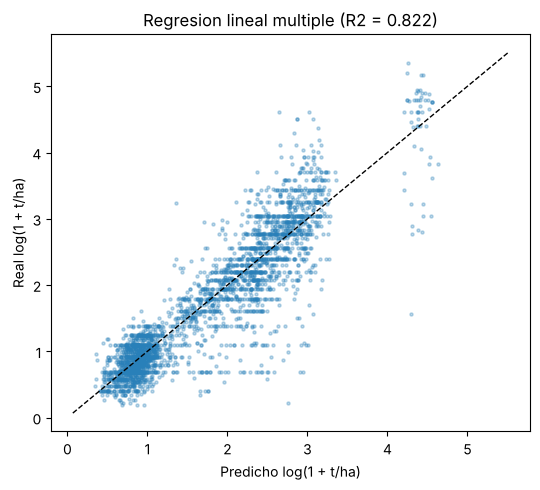

In [26]:
dr = d[d['rendimiento'].notna() & (d['rendimiento'] > 0)]
Xr = pd.concat([dr[['anio', 'log_area_sembrada']],
                pd.get_dummies(dr[['departamento', 'cultivo', 'temporada']], dtype=int)], axis=1)
yr = np.log1p(dr['rendimiento'])

Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, test_size=0.20, random_state=42)
lin_reg = LinearRegression().fit(Xr_train, yr_train)
pred_rend = lin_reg.predict(Xr_test)

print('REGRESION LINEAL MULTIPLE - log(1 + rendimiento)')
print('-' * 52)
print('Registros usados : {:,}'.format(len(dr)))
print('R2               : {:.4f}'.format(r2_score(yr_test, pred_rend)))
print('MAE              : {:.4f}'.format(mean_absolute_error(yr_test, pred_rend)))
print('RMSE             : {:.4f}'.format(np.sqrt(mean_squared_error(yr_test, pred_rend))))

muestra = np.random.choice(len(yr_test), 3000, replace=False)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(pred_rend[muestra], yr_test.iloc[muestra], s=5, alpha=0.3, color='#2980B9')
lims = [yr_test.min(), yr_test.max()]; ax.plot(lims, lims, 'k--', lw=1)
ax.set_xlabel('Predicho log(1 + t/ha)'); ax.set_ylabel('Real log(1 + t/ha)')
ax.set_title('Regresion lineal multiple (R2 = {:.3f})'.format(r2_score(yr_test, pred_rend)))
plt.tight_layout(); plt.show()

---
## 12. Del modelo al usuario: consulta de riesgo

Es la función que ejecuta la plataforma cuando un productor (o un técnico de la UMATA) registra una siembra. Recibe
**departamento, municipio, cultivo, temporada, área sembrada y año**; busca automáticamente el **historial** de ese
cultivo en ese municipio en los datos oficiales y devuelve:

1. El **nivel de riesgo** de pérdida alta (bajo, medio, alto) y su probabilidad.
2. Las **reglas** del árbol que explican el resultado.
3. El **rendimiento esperado**.
4. Las **recomendaciones preventivas** (tabla fija construida por el equipo, no es aprendizaje automático).

In [27]:
RECOMENDACIONES = {
    'ALTO' : ['Priorizar visita de la UMATA / ICA antes de la cosecha.',
              'Revisar drenajes y reservorios de agua (exceso o falta de lluvia son causas frecuentes).',
              'Consultar el seguro agropecuario (FINAGRO) para proteger la inversion.',
              'Escalonar la siembra o diversificar con otro cultivo para no concentrar el riesgo.'],
    'MEDIO': ['Monitorear el cultivo cada semana y reportar cualquier dano en la aplicacion.',
              'Usar semilla certificada y variedades adaptadas a la zona.'],
    'BAJO' : ['Mantener las buenas practicas actuales y registrar la cosecha para mejorar el historial.'],
}

def nivel(p):
    return 'ALTO' if p >= 0.70 else ('MEDIO' if p >= 0.50 else 'BAJO')

def regla_del_arbol(entrada):
    t = arbol.tree_
    pasos = []
    for n in arbol.decision_path(entrada).indices:
        if t.children_left[n] == t.children_right[n]:
            continue
        var, umbral = X.columns[t.feature[n]], t.threshold[n]
        valor = entrada.iloc[0][var]
        signo = '<=' if valor <= umbral else '>'
        if var.split('_')[0] in ('departamento', 'grupo', 'cultivo', 'temporada', 'ciclo'):
            pasos.append(f'{var} = {"si" if valor == 1 else "no"}')
        else:
            pasos.append(f'{var} = {valor:.2f}  ({signo} {umbral:.2f})')
    return pasos

def consultar_riesgo(departamento, municipio, cultivo, temporada, area_sembrada, anio):
    orden_t = {'A': 1, 'B': 2, 'Anual': 3}[temporada]
    hist = d[(d.departamento == departamento) & (d.municipio == municipio) & (d.cultivo == cultivo) &
             ((d.anio < anio) | ((d.anio == anio) & (d.orden < orden_t)))]
    fila = {c: 0 for c in X.columns}
    fila.update({'log_area_sembrada': np.log1p(area_sembrada),
                 'perdida_historica': hist.tasa_perdida.mean() if len(hist) else PERDIDA_MEDIA,
                 'perdida_anterior' : hist.tasa_perdida.iloc[-1] if len(hist) else PERDIDA_MEDIA,
                 'temporadas_previas': len(hist), 'sin_historial': int(len(hist) == 0)})
    info = d[d.cultivo == cultivo].iloc[0]
    for var, val in [('departamento', departamento), ('grupo', info.grupo), ('cultivo', cultivo),
                     ('temporada', temporada), ('ciclo', info.ciclo)]:
        if f'{var}_{val}' in fila:
            fila[f'{var}_{val}'] = 1
    entrada = pd.DataFrame([fila], columns=X.columns)
    p_arbol = arbol.predict_proba(entrada)[0, 1]
    p_log   = log_reg.predict_proba(escalador.transform(entrada))[0, 1]

    fr = {c: 0 for c in Xr.columns}
    fr.update({'anio': anio, 'log_area_sembrada': np.log1p(area_sembrada)})
    for var, val in [('departamento', departamento), ('cultivo', cultivo), ('temporada', temporada)]:
        if f'{var}_{val}' in fr:
            fr[f'{var}_{val}'] = 1
    rend = np.expm1(lin_reg.predict(pd.DataFrame([fr], columns=Xr.columns))[0])

    print('=' * 74)
    print('   AGRORIESGO IA - CONSULTA DE RIESGO DE PERDIDA')
    print('=' * 74)
    print(f'  Siembra             : {cultivo} · {municipio} ({departamento}) · {anio}-{temporada}')
    print(f'  Area sembrada       : {area_sembrada:,.0f} ha')
    print(f'  Historial municipal : {len(hist)} temporadas previas, perdida media '
          f'{(hist.tasa_perdida.mean() if len(hist) else PERDIDA_MEDIA):.1%}')
    print('-' * 74)
    print(f'  Riesgo de perdida alta : {nivel(p_arbol)}  (arbol {p_arbol:.0%} · reg. logistica {p_log:.0%})')
    print('  Por que (reglas del arbol):')
    for paso in regla_del_arbol(entrada)[:5]:
        print(f'      - {paso}')
    print(f'  Rendimiento esperado   : {rend:.1f} t/ha  ->  produccion estimada {rend * area_sembrada:,.0f} t')
    print('-' * 74)
    print('  Recomendaciones:')
    for r in RECOMENDACIONES[nivel(p_arbol)]:
        print(f'      - {r}')
    print('=' * 74)
    return p_arbol

print('Funcion de consulta definida')

Funcion de consulta definida


### Casos de demostración

Se toman combinaciones reales del conjunto de datos para mostrar distintos niveles de riesgo.

In [28]:
riesgo_por_caso = pd.Series(arbol.predict_proba(X)[:, 1], index=d.index)
d_2017 = d[d.anio == 2017].assign(riesgo=riesgo_por_caso)

alto = d_2017[d_2017.cultivo == 'MAIZ TRADICIONAL'].sort_values('riesgo', ascending=False).iloc[0]
_ = consultar_riesgo(alto.departamento, alto.municipio, alto.cultivo, alto.temporada, alto.area_sembrada, 2017)
print('Resultado real registrado en EVA: perdida de {:.0%} del area sembrada'.format(alto.tasa_perdida))

   AGRORIESGO IA - CONSULTA DE RIESGO DE PERDIDA
  Siembra             : MAIZ TRADICIONAL · ARIGUANI (MAGDALENA) · 2017-B
  Area sembrada       : 1,000 ha
  Historial municipal : 22 temporadas previas, perdida media 16.9%
--------------------------------------------------------------------------
  Riesgo de perdida alta : ALTO  (arbol 91% · reg. logistica 86%)
  Por que (reglas del arbol):
      - perdida_anterior = 0.38  (> 0.12)
      - perdida_anterior = 0.38  (> 0.19)
      - perdida_historica = 0.17  (> 0.13)
      - log_area_sembrada = 6.91  (> 1.24)
      - perdida_historica = 0.17  (<= 0.23)
  Rendimiento esperado   : 1.1 t/ha  ->  produccion estimada 1,140 t
--------------------------------------------------------------------------
  Recomendaciones:
      - Priorizar visita de la UMATA / ICA antes de la cosecha.
      - Revisar drenajes y reservorios de agua (exceso o falta de lluvia son causas frecuentes).
      - Consultar el seguro agropecuario (FINAGRO) para proteger la i

In [29]:
bajo = d_2017[d_2017.cultivo == 'PAPA'].sort_values('riesgo').iloc[0]
_ = consultar_riesgo(bajo.departamento, bajo.municipio, bajo.cultivo, bajo.temporada, bajo.area_sembrada, 2017)
print('Resultado real registrado en EVA: perdida de {:.0%} del area sembrada'.format(bajo.tasa_perdida))

   AGRORIESGO IA - CONSULTA DE RIESGO DE PERDIDA
  Siembra             : PAPA · SOATA (BOYACA) · 2017-B
  Area sembrada       : 5 ha
  Historial municipal : 18 temporadas previas, perdida media 4.2%
--------------------------------------------------------------------------
  Riesgo de perdida alta : BAJO  (arbol 0% · reg. logistica 39%)
  Por que (reglas del arbol):
      - perdida_anterior = 0.12  (> 0.12)
      - perdida_anterior = 0.12  (<= 0.19)
      - perdida_historica = 0.04  (<= 0.13)
      - log_area_sembrada = 1.79  (<= 1.87)
      - cultivo_PEPINO COHOMBRO = no
  Rendimiento esperado   : 11.9 t/ha  ->  produccion estimada 59 t
--------------------------------------------------------------------------
  Recomendaciones:
      - Mantener las buenas practicas actuales y registrar la cosecha para mejorar el historial.
Resultado real registrado en EVA: perdida de 0% del area sembrada


In [30]:
medio = d_2017[(d_2017.riesgo >= 0.5) & (d_2017.riesgo < 0.7) & (d_2017.cultivo == 'FRIJOL ARBUSTIVO')].iloc[0]
_ = consultar_riesgo(medio.departamento, medio.municipio, medio.cultivo, medio.temporada, medio.area_sembrada, 2017)
print('Resultado real registrado en EVA: perdida de {:.0%} del area sembrada'.format(medio.tasa_perdida))

   AGRORIESGO IA - CONSULTA DE RIESGO DE PERDIDA
  Siembra             : FRIJOL ARBUSTIVO · MEDELLIN (ANTIOQUIA) · 2017-A
  Area sembrada       : 10 ha
  Historial municipal : 20 temporadas previas, perdida media 9.3%
--------------------------------------------------------------------------
  Riesgo de perdida alta : MEDIO  (arbol 53% · reg. logistica 60%)
  Por que (reglas del arbol):
      - perdida_anterior = 0.17  (> 0.12)
      - perdida_anterior = 0.17  (<= 0.19)
      - perdida_historica = 0.09  (<= 0.13)
      - log_area_sembrada = 2.40  (> 1.87)
      - departamento_MAGDALENA = no
  Rendimiento esperado   : 0.8 t/ha  ->  produccion estimada 8 t
--------------------------------------------------------------------------
  Recomendaciones:
      - Monitorear el cultivo cada semana y reportar cualquier dano en la aplicacion.
      - Usar semilla certificada y variedades adaptadas a la zona.
Resultado real registrado en EVA: perdida de 20% del area sembrada


### 12.1 Panel del extensionista

El mismo modelo, aplicado a todos los registros de un departamento, produce el **listado priorizado** que vería la
secretaría de agricultura. Ejemplo con los registros de 2017 de un departamento:

In [31]:
DEPTO = d_2017.departamento.value_counts().index[0]
panel = (d_2017[d_2017.departamento == DEPTO]
         .assign(nivel=lambda x: x.riesgo.apply(nivel))
         .sort_values('riesgo', ascending=False)
         [['municipio', 'cultivo', 'temporada', 'area_sembrada', 'riesgo', 'nivel', 'tasa_perdida']]
         .head(10))
panel['riesgo'] = (panel['riesgo'] * 100).round(0).astype(int).astype(str) + ' %'
panel['tasa_perdida'] = (panel['tasa_perdida'] * 100).round(0).astype(int).astype(str) + ' %'
print('Departamento:', DEPTO, '- 10 siembras con mayor riesgo (2017)')
panel.rename(columns={'tasa_perdida': 'perdida_real'})

Departamento: BOYACA - 10 siembras con mayor riesgo (2017)


,municipio,cultivo,temporada,area_sembrada,riesgo,nivel,perdida_real
27719,TUTA,MAIZ TRADICIONAL,A,40,88 %,ALTO,50 %
27720,TUTA,MAIZ TRADICIONAL,B,20,88 %,ALTO,0 %
16117,BUSBANZA,PAPA,A,4,88 %,ALTO,50 %
16520,CHINAVITA,SAGU,Anual,8,88 %,ALTO,25 %
24694,SIACHOQUE,QUINUA,A,25,88 %,ALTO,0 %
16323,CAMPOHERMOSO,YUCA,Anual,80,88 %,ALTO,25 %
16077,BUSBANZA,FRIJOL,A,50,88 %,ALTO,40 %
24292,SATIVANORTE,AHUYAMA,B,3,88 %,ALTO,33 %
17728,CUCAITA,MAIZ TRADICIONAL,B,10,88 %,ALTO,10 %
21359,OICATA,AVENA,A,20,88 %,ALTO,20 %


---
## 13. Verificación: ¿el modelo sirve para predecir el futuro?

En el uso real, el modelo se entrena con años pasados y se aplica a temporadas que todavía no han ocurrido. Para
verificarlo, se entrena el mismo árbol **solo con 2006–2015** y se evalúa con **2016–2017**, años que el modelo
nunca vio.

In [32]:
pasado, futuro = (d.anio <= 2015).values, (d.anio >= 2016).values
arbol_t = DecisionTreeClassifier(max_depth=PROFUNDIDAD, class_weight='balanced', random_state=42)
arbol_t.fit(X[pasado], y[pasado])
pred_t, proba_t = arbol_t.predict(X[futuro]), arbol_t.predict_proba(X[futuro])[:, 1]

orden_t = np.argsort(-proba_t); reales_t = y[futuro].values[orden_t]
cobertura_20 = reales_t[:int(len(reales_t) * 0.2)].sum() / reales_t.sum()

validacion_temporal = pd.DataFrame({
    'Division aleatoria (numeral 7)': [accuracy_score(y_test, pred_arbol), recall_score(y_test, pred_arbol),
                                       f1_score(y_test, pred_arbol), roc_auc_score(y_test, proba_arbol)],
    'Entrena 2006-2015 / prueba 2016-2017': [accuracy_score(y[futuro], pred_t), recall_score(y[futuro], pred_t),
                                             f1_score(y[futuro], pred_t), roc_auc_score(y[futuro], proba_t)],
}, index=['Exactitud', 'Sensibilidad', 'F1-Score', 'AUC-ROC']).round(4)
print('Registros 2016-2017:', futuro.sum(), '· con perdida alta: {:.1%}'.format(y[futuro].mean()))
print('Visitando el 20 % de mayor riesgo en 2016-2017 se detecta el {:.1%} de las perdidas altas'.format(cobertura_20))
validacion_temporal

Registros 2016-2017: 22077 · con perdida alta: 14.9%
Visitando el 20 % de mayor riesgo en 2016-2017 se detecta el 55.2% de las perdidas altas


,Division aleatoria (numeral 7),Entrena 2006-2015 / prueba 2016-2017
Exactitud,0.7736,0.7493
Sensibilidad,0.5909,0.6713
F1-Score,0.4526,0.4436
AUC-ROC,0.7671,0.7770


---
## 14. Conclusiones

In [33]:
print(f'''
1. El problema se resolvio como APRENDIZAJE SUPERVISADO con datos oficiales colombianos (EVA, Ministerio de
   Agricultura, datos.gov.co): {len(d):,} registros de cultivos transitorios y anuales, cada uno con sus variables
   (X) y su resultado conocido (y = perdida alta o no), despues de una limpieza documentada.

2. Clasificacion: el arbol de decision detecta el {recall_score(y_test, pred_arbol):.0%} de las perdidas altas
   reales (sensibilidad) con un AUC-ROC de {roc_auc_score(y_test, proba_arbol):.2f}. La linea base que dice siempre
   "sin perdida" tiene {linea_base:.0%} de exactitud pero 0 % de sensibilidad: no sirve para alertar.

3. Priorizacion: visitando solo el 20 % de los casos de mayor riesgo se detecta el
   {priorizacion.iloc[1, 1]:.0f} % de las perdidas altas, frente al 20 % que se lograria visitando al azar.

4. La variable mas influyente es el historial de perdidas del mismo cultivo en el mismo municipio: los
   lugares que han perdido cosechas tienden a volver a perderlas, lo que justifica focalizar alli la asistencia.

5. Regresion: el modelo lineal multiple estima el rendimiento con un R2 de {r2_score(yr_test, pred_rend):.2f}.

6. La verificacion temporal (entrena 2006-2015, prueba 2016-2017) mantiene un AUC de
   {roc_auc_score(y[futuro], proba_t):.2f}: el modelo sirve para anticipar temporadas futuras.

7. Calidad de datos: el ano 2018 se excluyo porque sus cifras son preliminares (casi sin perdidas
   registradas); usarlo habria ensenado al modelo un patron falso.

8. Limitacion: EVA no incluye clima, plagas ni precios, que explican buena parte de las perdidas. Integrar datos del
   IDEAM y reportes fitosanitarios del ICA es el siguiente paso para mejorar la precision.
''')


1. El problema se resolvio como APRENDIZAJE SUPERVISADO con datos oficiales colombianos (EVA, Ministerio de
   Agricultura, datos.gov.co): 116,314 registros de cultivos transitorios y anuales, cada uno con sus variables
   (X) y su resultado conocido (y = perdida alta o no), despues de una limpieza documentada.

2. Clasificacion: el arbol de decision detecta el 59% de las perdidas altas
   reales (sensibilidad) con un AUC-ROC de 0.77. La linea base que dice siempre
   "sin perdida" tiene 84% de exactitud pero 0 % de sensibilidad: no sirve para alertar.

3. Priorizacion: visitando solo el 20 % de los casos de mayor riesgo se detecta el
   53 % de las perdidas altas, frente al 20 % que se lograria visitando al azar.

4. La variable mas influyente es el historial de perdidas del mismo cultivo en el mismo municipio: los
   lugares que han perdido cosechas tienden a volver a perderlas, lo que justifica focalizar alli la asistencia.

5. Regresion: el modelo lineal multiple estima el rendimi